In [ ]:
#  import dependencies

from langgraph.graph import StateGraph , START, END
from typing import TypedDict, Annotated, Literal
from langchain_openai import ChatOpenAI
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os
from langgraph.checkpoint.memory import MemorySaver
import operator # 
from pydantic import BaseModel, Field
# Field lets you add extra rules and metadata to individual fields.---> in simple terms, these are contraints
# BaseModel lets you define what fields an object should contain and what types those fields should have.
# Pydantic helps you define the structure of data and validate whether the data follows your rules.

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key="your API key"
)
print(model)

metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x000002C6C6554180> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002C6C6554B00> model_name='openai/gpt-oss-120b' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********')


In [35]:
# quadratic equation
ax**2 + bx + c = 0

# dicriminant
d = b**2 - 4ac

d > 0 then
2 real roots

d = 0 then 
1 real root

d > 0 then 
no real roots


SyntaxError: invalid decimal literal (2993818249.py, line 5)

In [36]:
class Quadratic_eqn(TypedDict):
    a : int
    b : int
    c : int

    equation : str
    discriminant : float
    result : str 
    root1 : int
    root2 : int


In [39]:
def equation(state : Quadratic_eqn):
    equation = f'({state['a']}x**2) + ({state['b']}x ) + ({state['c']})'

    return {'equation' :equation}

def calc_discriminants(state : Quadratic_eqn):
    discriminant = state['b']**2 - 4*state['a']*state['c']

    return {'discriminant' : discriminant}

def two_real_roots(state : Quadratic_eqn):

    root1 = (-state['b'] + state['discriminant']**0.5)/(2*state['a'])
    root2 = (-state['b'] - state['discriminant']**0.5)/(2*state['a'])

    result = f'the roots are {root1} and {root2}'

    return {'result' : result}

def one_real_root(state:Quadratic_eqn ):
    root = (-state['b'])/(2*state['a'])
    result = f'only repeating root is {root}'

    return {'result': result}

def No_real_root(state : Quadratic_eqn):
    result = f'No real roots'
    return {'result' : result}

def chk_condition(state: Quadratic_eqn)  -> Literal['two_real_roots','one_real_root', 'No_real_root']:
    if state['discriminant'] > 0:
        return "two_real_roots"
    elif state['discriminant'] == 0 :
        return "one_real_root"
    else:
        return "No_real_root"

        






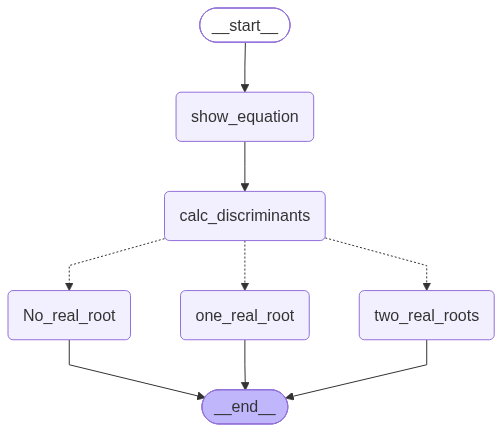

In [40]:
# graph
graph = StateGraph(Quadratic_eqn)


# node
graph.add_node('show_equation', equation)
graph.add_node('calc_discriminants', calc_discriminants)
graph.add_node('two_real_roots', two_real_roots)
graph.add_node('one_real_root', one_real_root)
graph.add_node('No_real_root', No_real_root)


#edge
graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calc_discriminants')
# condnal edge
graph.add_conditional_edges('calc_discriminants', chk_condition)
graph.add_edge('two_real_roots', END)
graph.add_edge('one_real_root', END)
graph.add_edge('No_real_root', END)


# compile 
workflow = graph.compile()

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())